# Crime Incident Analysis
## Phase 2: Exploratory and Statistical Data Analysis

**Google Colab notebook — final**

Outputs were calculated from the supplied CSV in Python and saved here; execution was not performed in a live Colab session. Upload this notebook using **File → Upload notebook**. To rerun, select **Runtime → Run all**, then upload the original CSV when prompted. Phase 1 does not need to be open: its essential cleaning is repeated below.

**Objectives:** central tendency (ungrouped and grouped), dispersion, skewness and kurtosis, IQR outliers, proximity measures, and supporting visuals. A static summary dashboard is included; detailed interactive dashboard design belongs to Phase 3.

**Statistical choice:** Location codes and record IDs are categories, so their averages are not calculated. Recorded incident time windows and daily report counts provide meaningful numerical measurements.

### 1. Load data and repeat essential Phase 1 cleaning
Missing timestamps remain missing. Counts use REPORT_DAT in UTC; no assumption is made that the report date equals the occurrence date.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial.distance import minkowski, cityblock, euclidean
from pathlib import Path

filename = "Crime_Incidents_in_the_Last_30_Days (1).csv"
if not Path(filename).exists():
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))

df = pd.read_csv(filename).drop_duplicates().copy()
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip().replace("", np.nan)
for col in ["WARD", "DISTRICT", "PSA", "CENSUS_TRACT"]:
    df[col] = df[col].astype("Int64").astype("string")
categories = ["BLOCK", "OFFENSE", "METHOD", "SHIFT", "WARD", "ANC",
              "DISTRICT", "PSA", "NEIGHBORHOOD_CLUSTER", "BLOCK_GROUP",
              "CENSUS_TRACT", "VOTING_PRECINCT", "BID"]
df[categories] = df[categories].fillna("Unknown")
df = df.drop(columns=["OCTO_RECORD_ID"])
for col in ["REPORT_DAT", "START_DATE", "END_DATE"]:
    df[col] = pd.to_datetime(df[col], format="%Y/%m/%d %H:%M:%S%z",
                             errors="coerce", utc=True)
df["Recorded_Interval_Hours"] = (
    df["END_DATE"] - df["START_DATE"]
).dt.total_seconds() / 3600
df.loc[df["Recorded_Interval_Hours"] < 0, "Recorded_Interval_Hours"] = np.nan
x = df["Recorded_Interval_Hours"].dropna()

plt.style.use("dark_background")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print("Incident records:", len(df))
print("Available recorded intervals:", len(x))
print("Missing recorded intervals:", df["Recorded_Interval_Hours"].isna().sum())
print("Report timestamps in UTC:", df["REPORT_DAT"].min(), "to", df["REPORT_DAT"].max())

Incident records: 2073
Available recorded intervals: 1895
Missing recorded intervals: 178
Report timestamps in UTC: 2026-09-23 07:09:57+00:00 to 2026-10-22 03:50:22+00:00


### 2. Ungrouped central tendency
Arithmetic mean = sum / n; median = middle value; mode = most frequent value. The geometric mean is computed only for **strictly positive intervals** because zero intervals prevent the usual logarithmic calculation. This positive-only result describes a different subset and is labelled accordingly.

In [2]:
positive = x[x > 0]
central = pd.DataFrame({
    "Measure": ["Arithmetic mean", "Median", "Mode", "Geometric mean (positive only)"],
    "Hours": [x.mean(), x.median(), x.mode().iloc[0], stats.gmean(positive)]
})
display(central.round(4))
print("All modes (hours):", x.mode().tolist())
print("Zero intervals excluded from geometric mean:", (x == 0).sum())
print("Positive intervals used:", len(positive))
display(df[["OFFENSE", "METHOD", "SHIFT"]].mode().head(1))

All modes (hours): [0.016666666666666666]
Zero intervals excluded from geometric mean: 50
Positive intervals used: 1845


,Measure,Hours
0,Arithmetic mean,17.8375
1,Median,1.0000
2,Mode,0.0167
3,Geometric mean (positive only),1.2010


,OFFENSE,METHOD,SHIFT
0,THEFT/OTHER,OTHERS,DAY


### 3. Grouped data and weighted mean
Create six equal-width classes covering all available intervals. Grouped mean, geometric mean, median and mode are **estimates** because class midpoints or within-class interpolation replace exact values. Weighted mean = Σ(midpoint × frequency) / Σfrequency. Midpoint geometric mean describes grouped midpoint values; it does not equal the positive-only ungrouped geometric mean. Classes are left-closed, right-open, with the last upper edge extended slightly to include the maximum.

In [3]:
edges = np.linspace(x.min(), x.max(), 7)
edges[-1] = np.nextafter(edges[-1], np.inf)
groups = pd.cut(x, bins=edges, right=False, include_lowest=True)
frequency = groups.value_counts(sort=False)
midpoints = (edges[:-1] + edges[1:]) / 2
width = edges[1] - edges[0]
grouped = pd.DataFrame({
    "Lower hours": edges[:-1], "Upper hours": edges[1:],
    "Midpoint": midpoints, "Frequency": frequency.values
})
grouped["Cumulative frequency"] = grouped["Frequency"].cumsum()
display(grouped.round(3))

f = grouped["Frequency"].to_numpy()
grouped_mean = np.average(midpoints, weights=f)
grouped_gmean = np.exp(np.average(np.log(midpoints), weights=f))
median_class = np.searchsorted(np.cumsum(f), len(x) / 2)
previous = np.cumsum(f)[median_class - 1] if median_class > 0 else 0
grouped_median = edges[median_class] + ((len(x)/2 - previous) / f[median_class]) * width
modal_class = int(np.argmax(f))
f1 = f[modal_class]
f0 = f[modal_class - 1] if modal_class > 0 else 0
f2 = f[modal_class + 1] if modal_class < len(f)-1 else 0
grouped_mode = edges[modal_class] + ((f1-f0) / (2*f1-f0-f2)) * width
display(pd.DataFrame({"Grouped estimate": ["Weighted arithmetic mean", "Geometric mean",
                                           "Median", "Mode"],
                      "Hours": [grouped_mean, grouped_gmean, grouped_median, grouped_mode]}).round(3))
print("Frequency total:", f.sum())

Frequency total: 1895


,Lower hours,Upper hours,Midpoint,Frequency,Cumulative frequency
0,0.0,884.0,442.0,1888,1888
1,884.0,1768.0,1326.0,4,1892
2,1768.0,2652.0,2210.0,2,1894
3,2652.0,3536.0,3094.0,0,1894
4,3536.0,4420.0,3978.0,0,1894
5,4420.0,5304.0,4862.0,1,1895


,Grouped estimate,Hours
0,Weighted arithmetic mean,448.064
1,Geometric mean,444.341
2,Median,443.639
3,Mode,442.469


**Interpretation:** Wide classes lose substantial detail near zero in a highly skewed dataset. Grouped estimates may differ greatly from exact statistics. The boundary modal class estimate uses an assumed zero frequency for the preceding class; treat it as illustrative. We will prioritize exact median and IQR in interpretation.

### 4. Dispersion
Sample variance and standard deviation use n−1. RMSD around the arithmetic mean uses n and therefore equals the population standard deviation. Coefficient of variation = sample SD / mean × 100. Quartile coefficient of dispersion = (Q3−Q1)/(Q3+Q1). These definitions are stated because “coefficient of dispersion” can refer to several measures.

In [4]:
q1, q2, q3 = x.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
rmsd = np.sqrt(np.mean((x - x.mean()) ** 2))
dispersion = pd.DataFrame({
    "Measure": ["Range (hours)", "Sample variance (hours squared)",
                "Sample standard deviation (hours)", "RMSD about mean (hours)",
                "IQR (hours)", "Coefficient of variation (%)", "Quartile coefficient of dispersion"],
    "Value": [x.max()-x.min(), x.var(ddof=1), x.std(ddof=1), rmsd, iqr,
              x.std(ddof=1)/x.mean()*100, iqr/(q3+q1)]
})
display(dispersion.round(4))

grouped_variance = np.sum(f * (midpoints - grouped_mean)**2) / (f.sum()-1)
display(pd.DataFrame({"Grouped estimate": ["Range between outer class boundaries (hours)",
    "Sample variance (hours squared)", "Sample standard deviation (hours)",
    "RMSD about grouped mean (hours)", "Coefficient of variation (%)"],
    "Value": [edges[-1]-edges[0], grouped_variance, np.sqrt(grouped_variance),
              np.sqrt(np.average((midpoints-grouped_mean)**2, weights=f)),
              np.sqrt(grouped_variance)/grouped_mean*100]}).round(4))

,Measure,Value
0,Range (hours),5304.0000
1,Sample variance (hours squared),24826.0216
2,Sample standard deviation (hours),157.5628
3,RMSD about mean (hours),157.5212
4,IQR (hours),2.7417
5,Coefficient of variation (%),883.3221
6,Quartile coefficient of dispersion,0.7815


,Grouped estimate,Value
0,Range between outer class boundaries (hours),5304.0000
1,Sample variance (hours squared),15229.2398
2,Sample standard deviation (hours),123.4068
3,RMSD about grouped mean (hours),123.3742
4,Coefficient of variation (%),27.5422


### 5. Distribution shape
Pearson’s second skewness = 3(mean−median)/sample SD. Bowley’s skewness = (Q3+Q1−2median)/IQR. Moment skewness uses the bias-corrected scipy estimator. Excess kurtosis compares against normal = 0; Pearson kurtosis compares against normal = 3. The similarly named Pearson measures are different statistics.

In [5]:
shape = pd.DataFrame({
    "Measure": ["Pearson second skewness", "Bowley skewness", "Moment skewness (bias corrected)",
                "Excess kurtosis (normal = 0)", "Pearson kurtosis (normal = 3)"],
    "Value": [3*(x.mean()-x.median())/x.std(ddof=1),
              (q3+q1-2*q2)/iqr,
              stats.skew(x, bias=False), stats.kurtosis(x, fisher=True, bias=False),
              stats.kurtosis(x, fisher=False, bias=False)]
})
display(shape.round(4))

,Measure,Value
0,Pearson second skewness,0.3206
1,Bowley skewness,0.5502
2,Moment skewness (bias corrected),23.8343
3,Excess kurtosis (normal = 0),713.7908
4,Pearson kurtosis (normal = 3),716.7908


### 6. IQR outlier investigation
Flag observations below Q1−1.5×IQR or above Q3+1.5×IQR. A statistical outlier is not automatically an error. Retain all records, show the longest windows, and compare summaries with and without flagged intervals.

In [6]:
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
df["Interval_IQR_Outlier"] = (
    (df["Recorded_Interval_Hours"] < lower)
    | (df["Recorded_Interval_Hours"] > upper)
)
flags = (x < lower) | (x > upper)
print(f"Q1: {q1:.3f}; Q3: {q3:.3f}; IQR: {iqr:.3f} hours")
print(f"Lower fence: {lower:.3f}; upper fence: {upper:.3f} hours")
print(f"Flagged: {flags.sum()} of {len(x)} valid intervals ({flags.mean()*100:.2f}%)")
display(df.nlargest(5, "Recorded_Interval_Hours")[[
    "CCN", "OFFENSE", "START_DATE", "END_DATE", "Recorded_Interval_Hours"]])
display(pd.DataFrame({
    "All valid intervals": x.agg(["count", "mean", "median", "std"]),
    "Unflagged intervals only": x[~flags].agg(["count", "mean", "median", "std"])
}).round(3))

Q1: 0.383; Q3: 3.125; IQR: 2.742 hours
Lower fence: -3.729; upper fence: 7.237 hours
Flagged: 348 of 1895 valid intervals (18.36%)


,CCN,OFFENSE,START_DATE,END_DATE,Recorded_Interval_Hours
852,26424058,THEFT/OTHER,2026-03-09 16:35:00+00:00,2026-10-16 16:35:00+00:00,5304.000000
809,26135887,THEFT/OTHER,2026-06-01 22:00:00+00:00,2026-09-05 19:00:00+00:00,2301.000000
635,26144579,THEFT/OTHER,2026-07-13 16:00:00+00:00,2026-10-07 16:00:00+00:00,2064.000000
1608,26139653,THEFT/OTHER,2026-08-06 16:00:00+00:00,2026-09-30 12:40:00+00:00,1316.666667
1571,26423722,THEFT/OTHER,2026-07-24 17:00:00+00:00,2026-09-12 17:00:00+00:00,1200.000000


,All valid intervals,Unflagged intervals only
count,1895.000,1547.000
mean,17.838,1.161
median,1.000,0.750
std,157.563,1.373


### 7. Distribution visuals
The full boxplot retains extreme windows. A second boxplot hides only outlier markers to make the central spread readable; data are not deleted. The histogram uses log(1+hours), which includes zero and exposes the long tail. The Q–Q plot checks normality visually on original hours; it is not a formal proof or test.

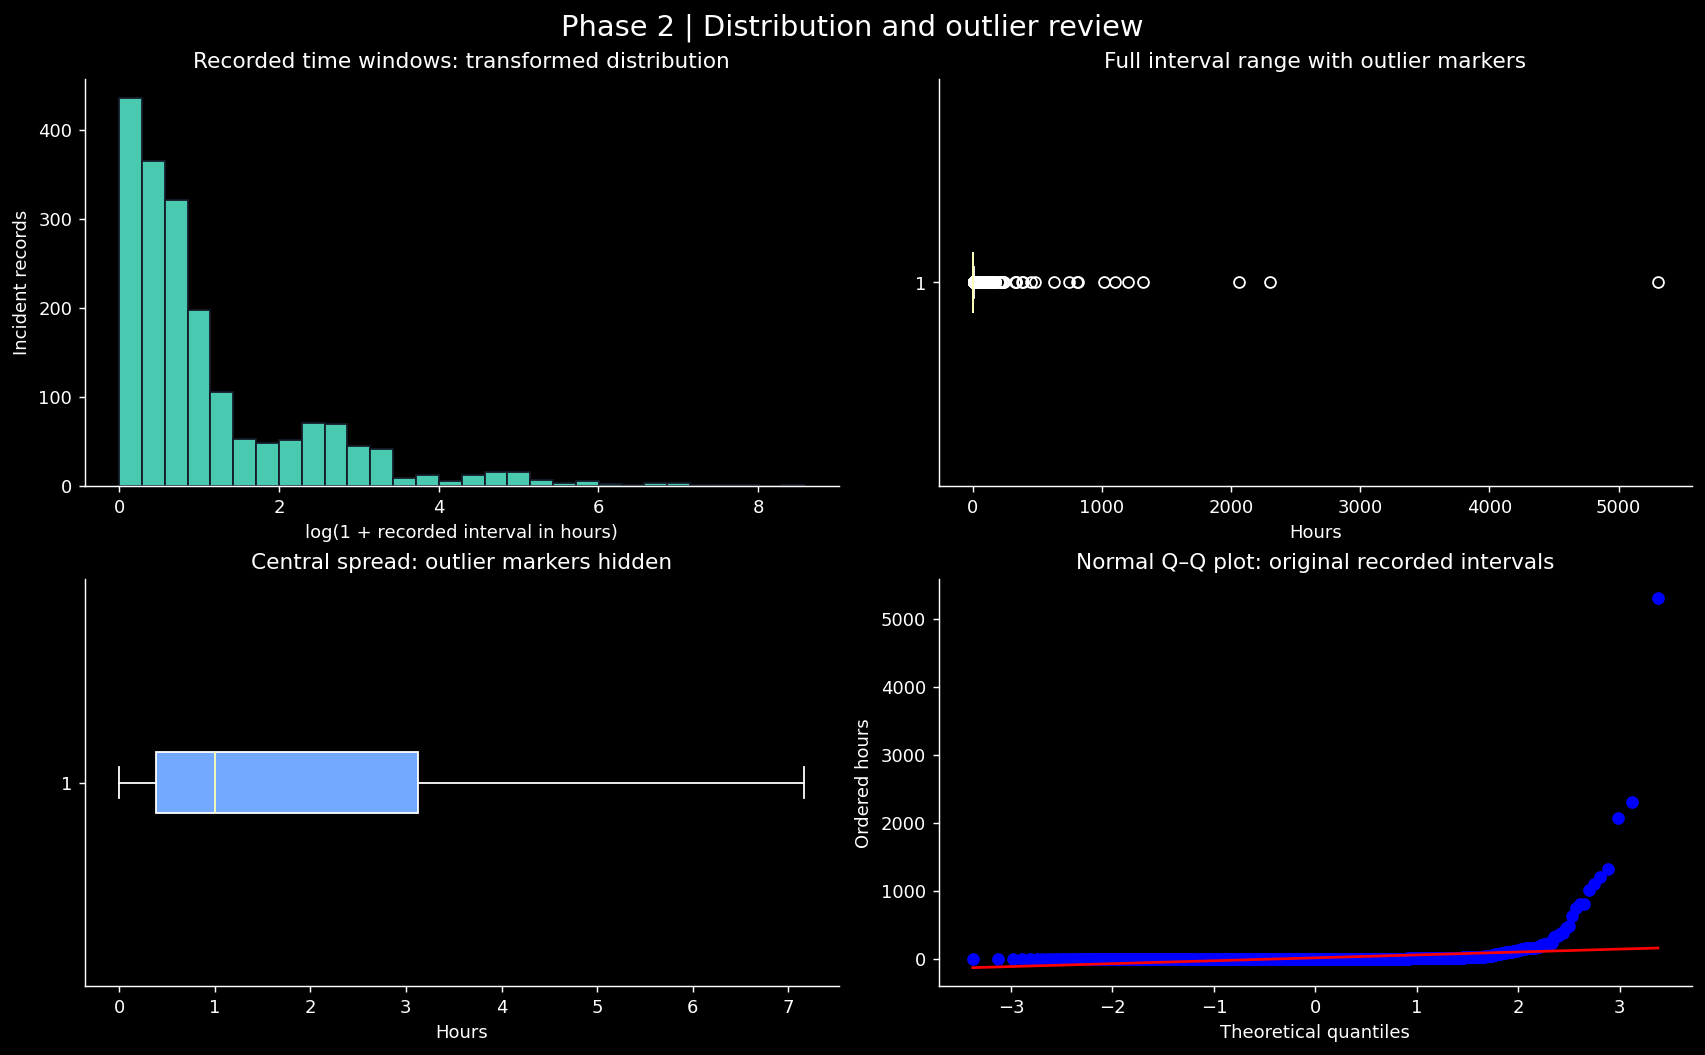

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
axes[0,0].hist(np.log1p(x), bins=30, color="#48c9b0", edgecolor="#151b28")
axes[0,0].set(title="Recorded time windows: transformed distribution",
              xlabel="log(1 + recorded interval in hours)", ylabel="Incident records")
axes[0,1].boxplot(x, vert=False, patch_artist=True,
                  boxprops={"facecolor":"#48c9b0"})
axes[0,1].set(title="Full interval range with outlier markers", xlabel="Hours")
axes[1,0].boxplot(x, vert=False, showfliers=False, patch_artist=True,
                  boxprops={"facecolor":"#73a9ff"})
axes[1,0].set(title="Central spread: outlier markers hidden", xlabel="Hours")
stats.probplot(x, dist="norm", plot=axes[1,1])
axes[1,1].set(title="Normal Q–Q plot: original recorded intervals", ylabel="Ordered hours")
fig.suptitle("Phase 2 | Distribution and outlier review", fontsize=16)
plt.show()

### 8. Daily report counts and a frequency-weighted mean
Count reports by UTC report date, including zero-count days between the observed minimum and maximum date. Boundary dates may be partial. The mean describes this file’s reporting window, not a long-term daily crime rate. A frequency-weighted mean of daily count values should equal the direct arithmetic mean.

In [8]:
report_dates = df["REPORT_DAT"].dropna().dt.floor("D")
date_range = pd.date_range(report_dates.min(), report_dates.max(), freq="D")
daily = report_dates.value_counts().reindex(date_range, fill_value=0).sort_index()
daily.name = "Reports"
count_frequency = daily.value_counts().sort_index()
weighted_daily_mean = np.average(count_frequency.index, weights=count_frequency.values)
print("Days in observed reporting window:", len(daily))
print("Records with missing report dates:", df["REPORT_DAT"].isna().sum())
print("Mean daily reports:", round(daily.mean(), 3))
print("Frequency-weighted mean:", round(weighted_daily_mean, 3))
display(daily.describe().to_frame().round(3))
assert np.isclose(daily.mean(), weighted_daily_mean)
assert daily.sum() == df["REPORT_DAT"].notna().sum()

Days in observed reporting window: 30
Records with missing report dates: 0
Mean daily reports: 69.1
Frequency-weighted mean: 69.1


,Reports
count,30.000
mean,69.100
std,16.522
min,10.000
25%,64.250
50%,73.500
75%,80.000
max,90.000


### 9. Numeric proximity: two incident locations
Use XBLOCK and YBLOCK, projected location coordinates, instead of treating latitude/longitude degrees as flat distances. Coordinates appear to be in metres; verify the source coordinate reference system before reporting physical distances. Values below are labelled **coordinate units**. Euclidean is straight-line separation, Manhattan is axis-aligned separation, and Minkowski p=3 is another numeric distance. These are not road travel distances. No normalization is needed because both axes have the same coordinate scale.

In [9]:
locations = df[["CCN", "XBLOCK", "YBLOCK"]].dropna().head(2)
display(locations)
a = locations.iloc[0][["XBLOCK", "YBLOCK"]].to_numpy(dtype=float)
b = locations.iloc[1][["XBLOCK", "YBLOCK"]].to_numpy(dtype=float)
display(pd.DataFrame({
    "Distance": ["Euclidean", "Manhattan", "Minkowski (p=3)"],
    "Coordinate units": [euclidean(a,b), cityblock(a,b), minkowski(a,b,p=3)]
}).round(3))

,CCN,XBLOCK,YBLOCK
0,26137330,397953.59,140415.23
1,26137481,398099.12,138058.27


,Distance,Coordinate units
0,Euclidean,2361.449
1,Manhattan,2502.490
2,Minkowski (p=3),2357.145


### 10. Binary proximity: SMC and Jaccard
Create three illustrative binary descriptors: gun method, theft-related offense, and midnight shift. Compare one gun-method record with one non-gun record. SMC includes shared zeros; Jaccard ignores shared zeros. This is descriptor similarity, not a risk score or a prediction.

In [10]:
binary = pd.DataFrame({
    "Gun method": (df["METHOD"] == "GUN").astype(int),
    "Theft-related": df["OFFENSE"].str.contains("THEFT", case=False, na=False).astype(int),
    "Midnight shift": (df["SHIFT"] == "MIDNIGHT").astype(int)
})
indices = [df.index[df["METHOD"] == "GUN"][0], df.index[df["METHOD"] != "GUN"][0]]
display(df.loc[indices, ["CCN", "OFFENSE", "METHOD", "SHIFT"]])
display(binary.loc[indices])
u, v = binary.loc[indices].to_numpy()
smc = np.mean(u == v)
intersection = np.sum((u == 1) & (v == 1))
union = np.sum((u == 1) | (v == 1))
jaccard = intersection / union if union else 1.0
print("SMC similarity:", round(smc, 4))
print("Jaccard similarity:", round(jaccard, 4))

SMC similarity: 0.3333
Jaccard similarity: 0.3333


,CCN,OFFENSE,METHOD,SHIFT
26,26136409,ASSAULT W/DANGEROUS WEAPON,GUN,MIDNIGHT
0,26137330,THEFT/OTHER,OTHERS,MIDNIGHT


,Gun method,Theft-related,Midnight shift
26,1,0,1
0,0,1,1


### 11. Text proximity: cosine similarity
Compare the first two distinct block descriptions using token counts. Cosine similarity measures shared word patterns, not geographical closeness. The record IDs and exact compared texts are displayed for reproducibility.

In [11]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

texts = df["BLOCK"].drop_duplicates().head(2)
display(texts.to_frame("Compared block description"))
vectorizer = CountVectorizer()
vectors = vectorizer.fit_transform(texts)
print("Cosine similarity:", round(cosine_similarity(vectors)[0,1], 4))

Cosine similarity: 0.4286


,Compared block description
0,3301 - 3399 BLOCK OF GEORGIA AVENUE NW
1,1500 - 1599 BLOCK OF 7TH STREET NW


### 12. Summary dashboard
This static overview combines headline indicators with report-date counts, offense composition and shift counts. Counts describe records in this file. They do not establish population-adjusted risk, causality, or the actual hour when every offense occurred.

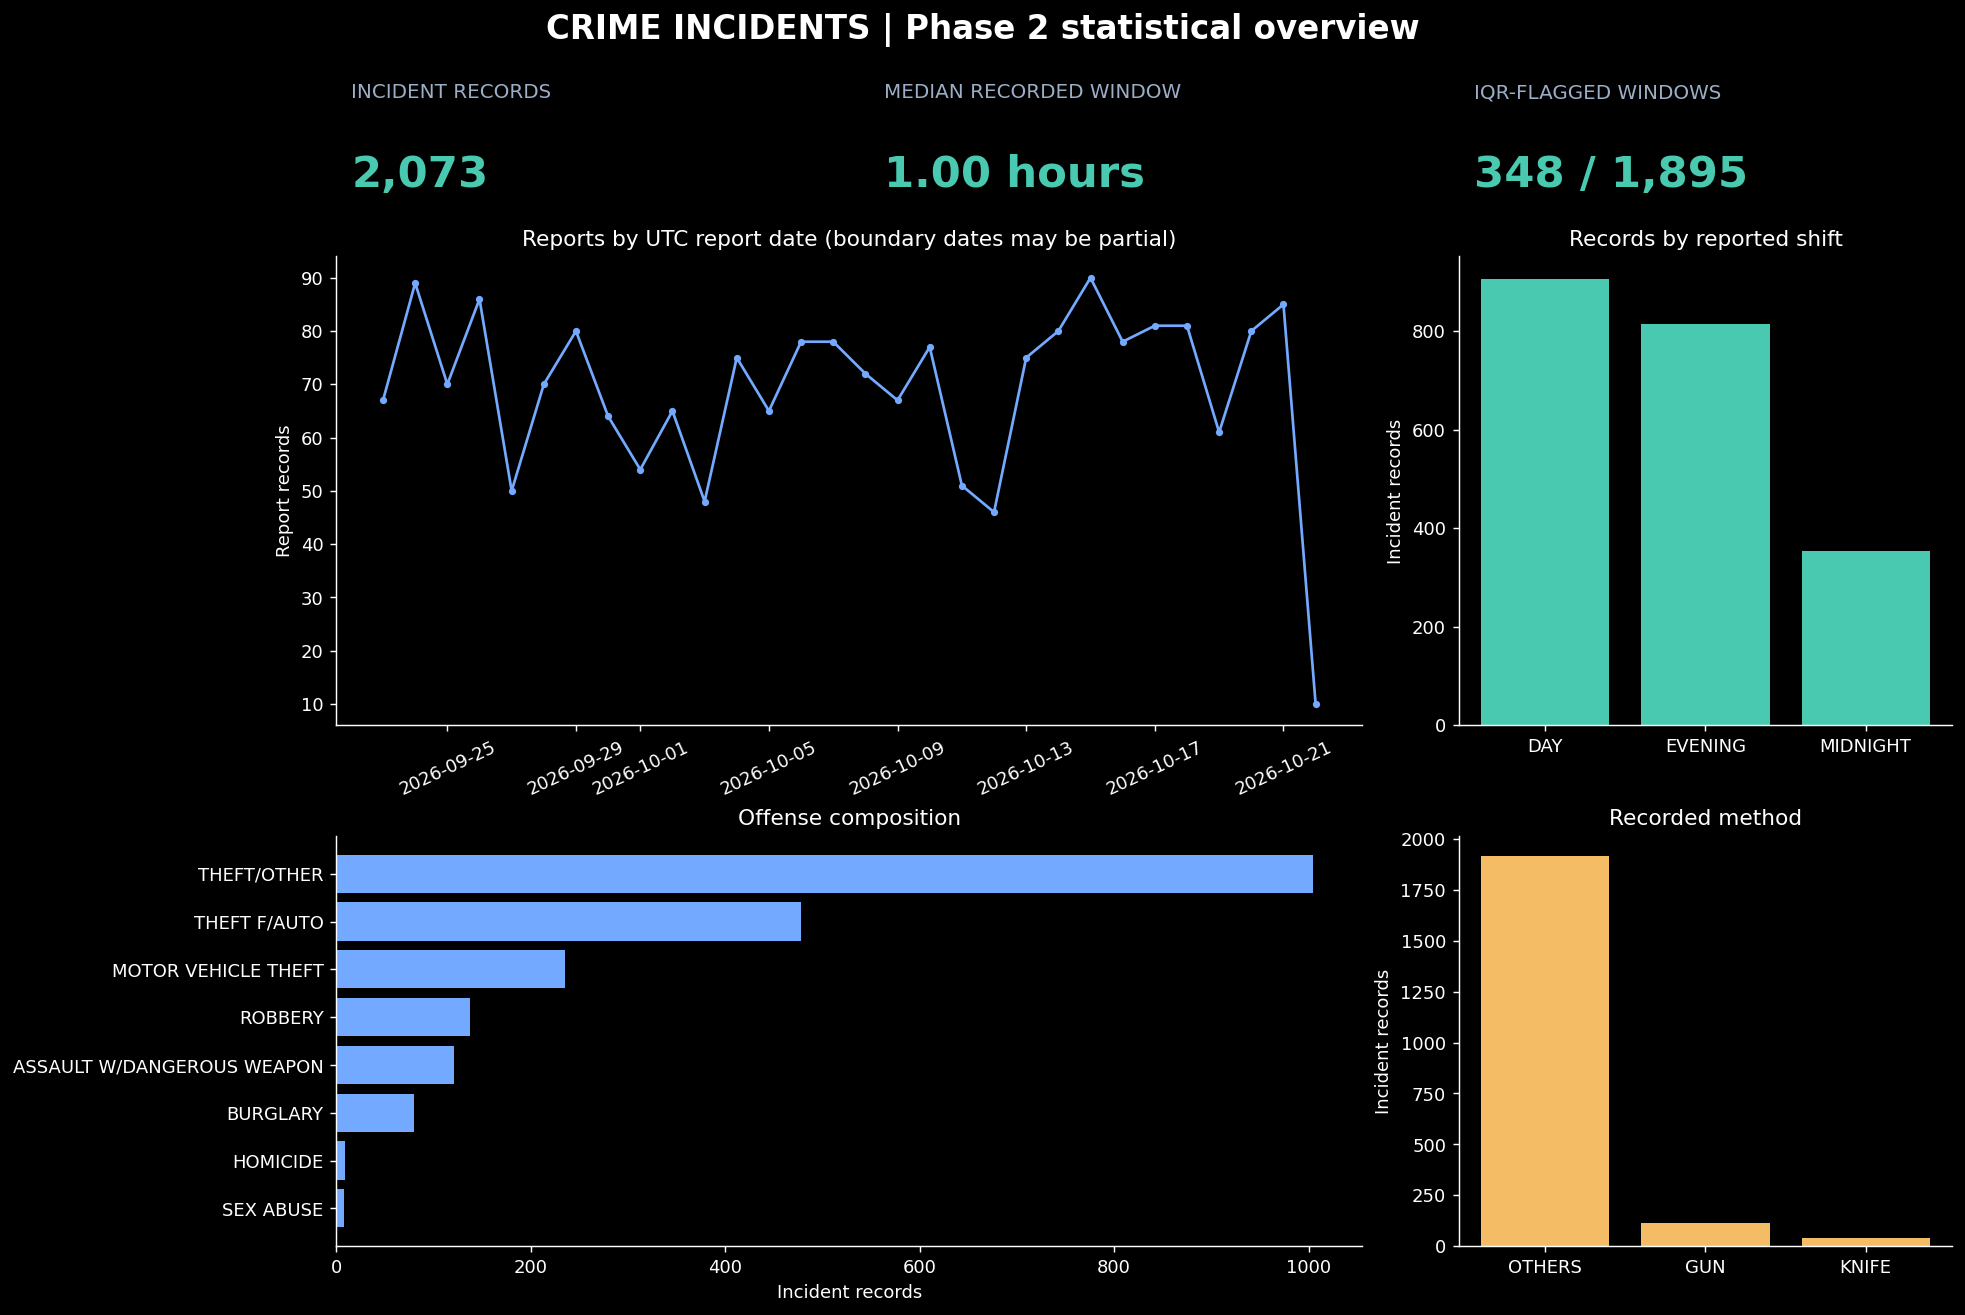

In [12]:
fig = plt.figure(figsize=(15, 10), constrained_layout=True)
grid = fig.add_gridspec(3, 3, height_ratios=[0.55, 1.6, 1.4])
kpis = [("INCIDENT RECORDS", f"{len(df):,}"),
        ("MEDIAN RECORDED WINDOW", f"{x.median():.2f} hours"),
        ("IQR-FLAGGED WINDOWS", f"{flags.sum():,} / {len(x):,}")]
for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(grid[0,i])
    ax.axis("off")
    ax.text(0.03, 0.75, label, color="#9baec6", fontsize=11)
    ax.text(0.03, 0.20, value, fontsize=24, color="#48c9b0", weight="bold")

ax = fig.add_subplot(grid[1,:2])
ax.plot(daily.index, daily.values, color="#73a9ff", marker="o", markersize=3)
ax.set(title="Reports by UTC report date (boundary dates may be partial)", ylabel="Report records")
ax.tick_params(axis="x", rotation=25)

ax = fig.add_subplot(grid[1,2])
shift_counts = df["SHIFT"].value_counts()
ax.bar(shift_counts.index, shift_counts.values, color="#48c9b0")
ax.set(title="Records by reported shift", ylabel="Incident records")

ax = fig.add_subplot(grid[2,:2])
offense_counts = df["OFFENSE"].value_counts().sort_values()
ax.barh(offense_counts.index, offense_counts.values, color="#73a9ff")
ax.set(title="Offense composition", xlabel="Incident records")

ax = fig.add_subplot(grid[2,2])
method_counts = df["METHOD"].value_counts()
ax.bar(method_counts.index, method_counts.values, color="#f3bc65")
ax.set(title="Recorded method", ylabel="Incident records")
fig.suptitle("CRIME INCIDENTS | Phase 2 statistical overview", fontsize=18, weight="bold")
plt.show()

### 13. Computed findings
These statements are generated from the uploaded data. Explanations for patterns require additional evidence; the file alone does not establish why they occurred.

In [13]:
top_offense = df["OFFENSE"].value_counts()
print(f"1. Most frequent offense: {top_offense.index[0]} "
      f"({top_offense.iloc[0]:,} records; {top_offense.iloc[0]/len(df)*100:.1f}%).")
print(f"2. Recorded interval mean = {x.mean():.2f} hours; median = {x.median():.2f} hours.")
print("   The mean is pulled upward by long recorded windows; use median and IQR together.")
print(f"3. IQR = {iqr:.2f} hours; {flags.sum()} intervals are flagged for review, not deleted.")
print(f"4. {df['Recorded_Interval_Hours'].isna().sum()} records lack a usable interval.")
print(f"5. Equal-width grouped mean ({grouped_mean:.2f} hours) differs from exact mean "
      f"({x.mean():.2f} hours), showing information loss from broad bins.")
print("6. Review long windows against source records before correcting them.")
print("7. Offense and shift counts can guide further questions; population and exposure data")
print("   would be needed for comparisons of risk across locations or time periods.")

1. Most frequent offense: THEFT/OTHER (1,005 records; 48.5%).
2. Recorded interval mean = 17.84 hours; median = 1.00 hours.
   The mean is pulled upward by long recorded windows; use median and IQR together.
3. IQR = 2.74 hours; 348 intervals are flagged for review, not deleted.
4. 178 records lack a usable interval.
5. Equal-width grouped mean (448.06 hours) differs from exact mean (17.84 hours), showing information loss from broad bins.
6. Review long windows against source records before correcting them.
7. Offense and shift counts can guide further questions; population and exposure data
   would be needed for comparisons of risk across locations or time periods.


### Phase 2 conclusion
Central tendency, grouped estimates, dispersion, shape measures and proximity calculations were demonstrated using meaningful features. Missing intervals were excluded only from interval-based calculations. IQR outliers were retained and compared with the unflagged subset. Supporting charts and a static dashboard show the distribution and record composition.

**Scope:** Phase 3 will expand chart selection and interactive exploration. Phase 4 will develop contextual interpretation and recommendations.

**Sources:** Supplied Crime_Incidents_in_the_Last_30_Days (1).csv; supplied FDS Mini Competition Guidelines and rubric. Statistical functions use pandas, NumPy, SciPy and scikit-learn. No external crime rates or causal claims are introduced.